<h1 align="center">🌸 Iris Flower Classification</h1>
<h3 align="center">Predicting iris species with machine learning</h3>

<p align="center"><b>Oasis Infobyte Internship Program (OIBSIP) · Data Science · Task 1</b></p>

---

| | |
|---|---|
| **Author** | Rini Ramadhan Naim |
| **Track** | Data Science |
| **Task** | Task 1 — Iris Flower Classification |
| **Tech stack** | Python · pandas · scikit-learn · matplotlib · seaborn · Jupyter Notebook |

---

## 🎯 Objective

Train machine learning models that identify the species of an iris flower
(**Setosa**, **Versicolor** or **Virginica**) from its four physical measurements,
then compare the models and declare the best one.

## 🗺️ Table of contents

1. [Setup](#1.-Setup)
2. [Load the dataset](#2.-Load-the-dataset)
3. [Exploratory data analysis (EDA)](#3.-Exploratory-data-analysis-(EDA))
4. [Visualisations](#4.-Visualisations)
5. [Feature selection discussion](#5.-Feature-selection-discussion)
6. [Train/test split](#6.-Train/test-split)
7. [Model training and evaluation](#7.-Model-training-and-evaluation)
8. [Model comparison and best model](#8.-Model-comparison-and-best-model)
9. [Feature importance and a new prediction](#9.-Feature-importance-and-a-new-prediction)
10. [Conclusion](#10.-Conclusion)

---
## 1. Setup

> **What happens here:** import the libraries, set a consistent plot style and print the
> library versions so the results are reproducible.

In [1]:
# Standard libraries
import sys
import warnings
warnings.filterwarnings("ignore")

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

# Global settings
RANDOM_STATE = 42                      # fixed seed so results can be repeated
sns.set_theme(style="whitegrid", context="notebook")
SPECIES_COLORS = {"setosa": "#4C72B0", "versicolor": "#DD8452", "virginica": "#55A868"}

# Library versions
print(f"Python  : {sys.version.split()[0]}")
print(f"pandas  : {pd.__version__}")
print(f"numpy   : {np.__version__}")
print(f"sklearn : {sklearn.__version__}")

Python  : 3.12.3
pandas  : 3.0.6
numpy   : 2.5.4
sklearn : 1.9.1


---
## 2. Load the dataset

> **What happens here:** the Iris dataset is built into scikit-learn, so no download is needed.
> It contains **150 flowers** (50 per species) described by **4 numeric measurements**.

| Feature | Meaning |
|---|---|
| `sepal length (cm)` | Length of the sepal (outer leaf) |
| `sepal width (cm)` | Width of the sepal |
| `petal length (cm)` | Length of the petal |
| `petal width (cm)` | Width of the petal |

In [2]:
# Load the dataset as a bunch object that also holds a pandas DataFrame
iris_dataset = load_iris(as_frame=True)

print("Keys of iris_dataset :", list(iris_dataset.keys()))
print("Target names         :", [str(n) for n in iris_dataset["target_names"]])
print("Feature names        :", iris_dataset["feature_names"])

Keys of iris_dataset : ['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']
Target names         : ['setosa', 'versicolor', 'virginica']
Feature names        : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [3]:
# Build one DataFrame with the features, the numeric target and the species name
df = iris_dataset["frame"].copy()
df["species"] = df["target"].map(dict(enumerate(iris_dataset["target_names"])))

FEATURES = iris_dataset["feature_names"]
TARGET_NAMES = [str(n) for n in iris_dataset["target_names"]]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


---
## 3. Exploratory data analysis (EDA)

> **What happens here:** check the shape, data types, missing values, duplicates,
> summary statistics and class balance before modelling.

In [4]:
# Shape and data types
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
print(df.dtypes)

Shape: 150 rows x 6 columns

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species                  str
dtype: object


In [5]:
# Missing values and duplicated rows
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nDuplicated rows: {df.duplicated().sum()}")

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Duplicated rows: 1


In [6]:
# Descriptive statistics of the four measurements
df[FEATURES].describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


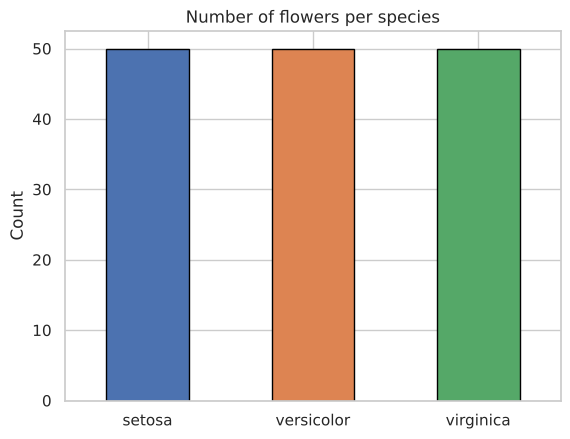

In [7]:
# Class balance: how many flowers of each species?
print(df["species"].value_counts())

ax = df["species"].value_counts().reindex(TARGET_NAMES).plot(
    kind="bar", color=[SPECIES_COLORS[s] for s in TARGET_NAMES], edgecolor="black")
ax.set_title("Number of flowers per species")
ax.set_xlabel("")
ax.set_ylabel("Count")
plt.xticks(rotation=0)
plt.show()

### 📝 EDA notes

- ✅ The dataset has **150 rows** and **4 numeric features**, plus the target.
- ✅ There are **no missing values**, so no imputation is needed.
- ℹ️ There is **1 duplicated row** (two flowers with identical measurements). It is kept, because identical
  measurements can happen for real flowers and one row has almost no effect on 150.
- ✅ The classes are **perfectly balanced** (50 / 50 / 50), so accuracy is a fair metric.
- ℹ️ The features are on a similar scale (about 0.1 to 8 cm), so scaling matters little. It is still applied for
  the distance-based and linear models to follow good practice.

---
## 4. Visualisations

> **What happens here:** look at the data to see which measurements separate the species.

### 4.1 Pairplot: every feature against every other feature

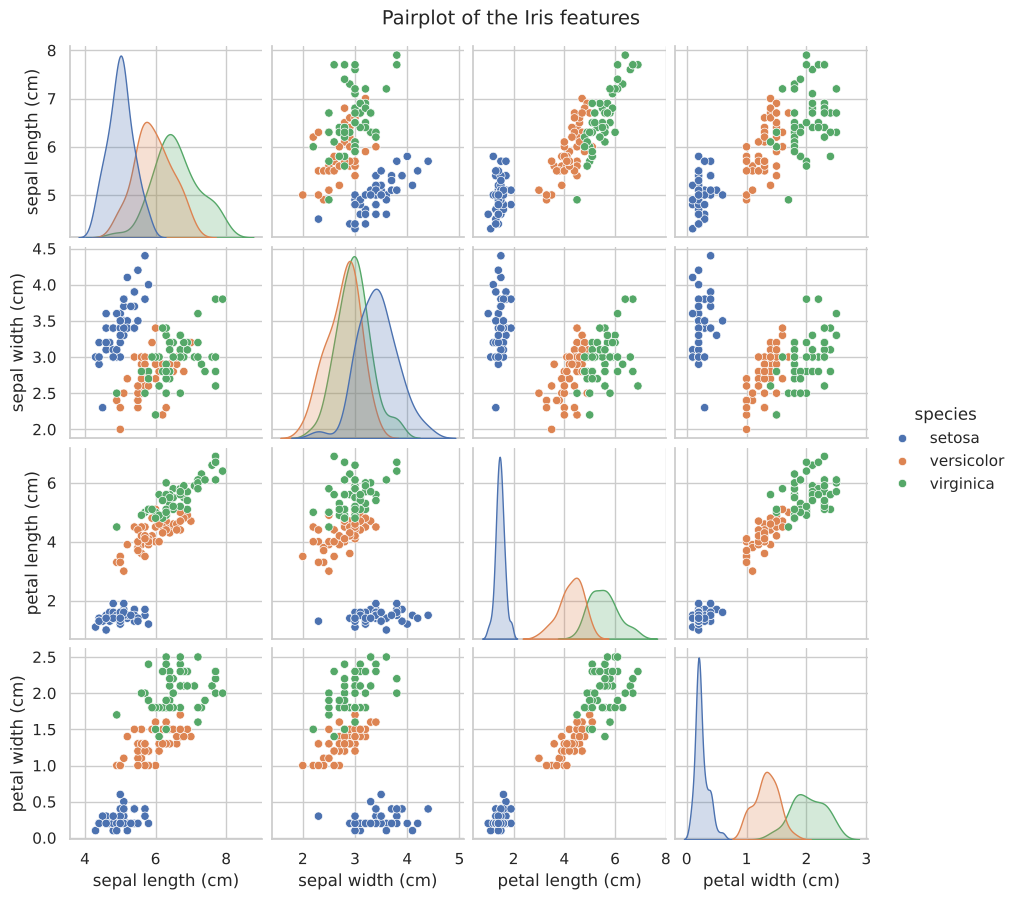

In [8]:
# Scatter plots for each pair of features, coloured by species (diagonal = distribution)
g = sns.pairplot(df[FEATURES + ["species"]], hue="species", palette=SPECIES_COLORS,
                 diag_kind="kde", corner=False, height=2.2)
g.figure.suptitle("Pairplot of the Iris features", y=1.02, fontsize=14)
plt.show()

### 4.2 Box plots: distribution of each feature by species

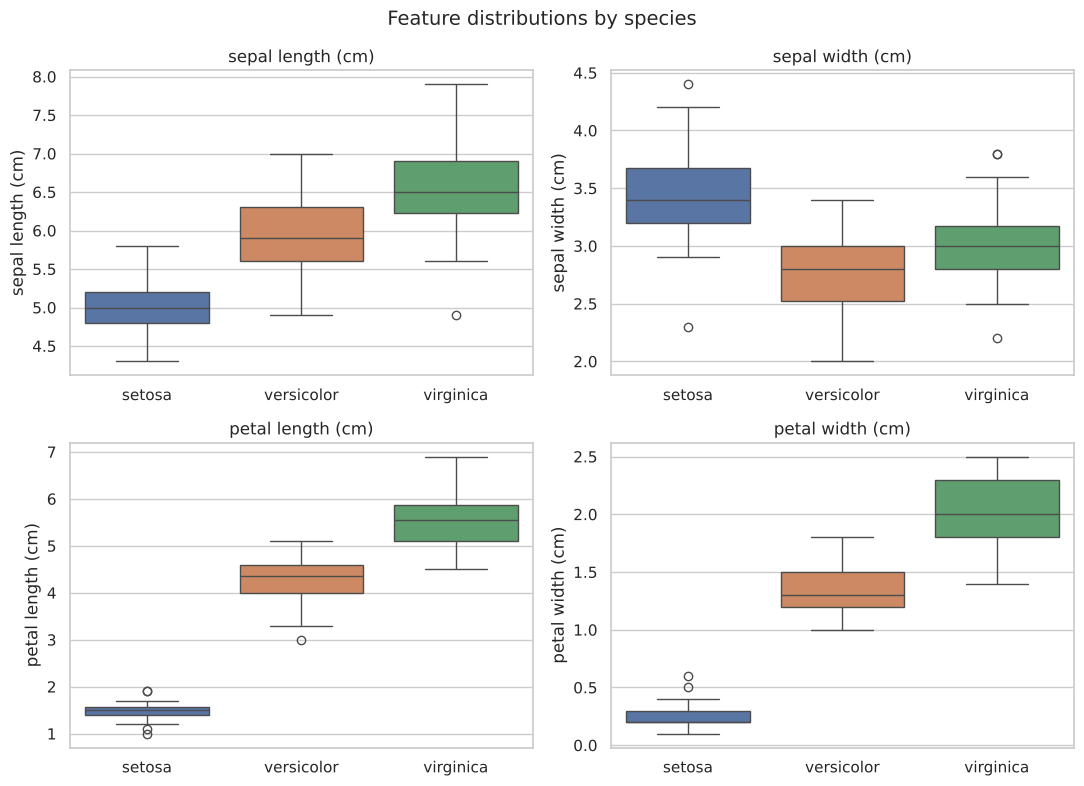

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feature in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x="species", y=feature, hue="species",
                palette=SPECIES_COLORS, order=TARGET_NAMES, legend=False, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
fig.suptitle("Feature distributions by species", fontsize=14)
plt.tight_layout()
plt.show()

### 4.3 Correlation heatmap

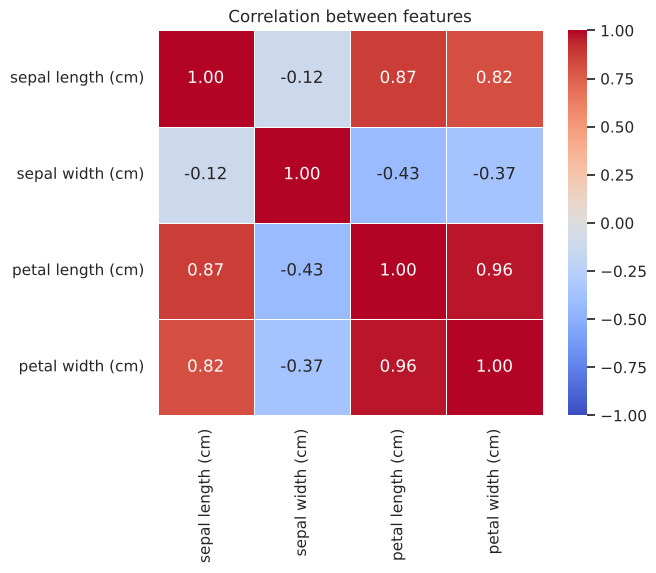

In [10]:
plt.figure(figsize=(6.5, 5))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation between features")
plt.show()

---
## 5. Feature selection discussion

> **Question:** which features are the most discriminative?

**Observations from the plots above:**

| Feature | What the plots show | Discriminative power |
|---|---|---|
| **Petal length** | Setosa is far below the other two with almost no overlap. Versicolor and Virginica barely overlap. | ⭐⭐⭐ Very high |
| **Petal width** | Same clear separation as petal length. | ⭐⭐⭐ Very high |
| **Sepal length** | Species overlap noticeably, mainly Versicolor and Virginica. | ⭐⭐ Medium |
| **Sepal width** | Strong overlap between all species. | ⭐ Low |

**Conclusions**

1. **Petal length and petal width** are the most useful features. They separate **Setosa** perfectly and
   separate **Versicolor** from **Virginica** well.
2. Petal length and petal width are **highly correlated** (about 0.96), so they carry similar information.
3. **Setosa** is linearly separable from the others. The only real difficulty is telling **Versicolor** from
   **Virginica**, where a few flowers sit close to the boundary.
4. This discussion is checked with numbers in [Section 9](#9.-Feature-importance-and-a-new-prediction).

All four features are still used for training, because the dataset is small and the extra features do no harm.

---
## 6. Train/test split

> **What happens here:** keep **80%** of the data for training and **20%** for testing, as required.
> `stratify=y` keeps the same species proportions in both parts, and `random_state` makes it repeatable.

In [11]:
X = iris_dataset["data"]
y = iris_dataset["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}    y_test : {y_test.shape}")
print("\nSpecies counts in the test set:")
print(pd.Series(y_test).map(dict(enumerate(TARGET_NAMES))).value_counts())

X_train: (120, 4)   y_train: (120,)
X_test : (30, 4)    y_test : (30,)

Species counts in the test set:
target
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


---
## 7. Model training and evaluation

> **What happens here:** train **four different classifiers** (the task asks for at least two) and
> evaluate each with **accuracy, a confusion matrix and a classification report**.

| Model | Idea in one line |
|---|---|
| **k-Nearest Neighbours (kNN)** | Looks at the 5 most similar flowers and takes a majority vote |
| **Logistic Regression** | Learns a linear boundary between the species |
| **Decision Tree** | Asks simple yes/no questions about the measurements |
| **Random Forest** | Combines many decision trees to get a more stable answer |

**Metric guide:** *precision* = of the flowers predicted as a species, how many were right;
*recall* = of the real flowers of a species, how many were found; *F1* = balance of the two.

In [12]:
# Define the models (scaling is wrapped in a pipeline for kNN and Logistic Regression)
models = {
    "k-Nearest Neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Logistic Regression":  make_pipeline(StandardScaler(), LogisticRegression(max_iter=200)),
    "Decision Tree":        DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "Random Forest":        RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

# Train every model and store its predictions on the test set
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"{name:<22} test accuracy = {accuracy_score(y_test, predictions[name]):.4f}")

k-Nearest Neighbours   test accuracy = 0.9333
Logistic Regression    test accuracy = 0.9333
Decision Tree          test accuracy = 0.9667


Random Forest          test accuracy = 0.9000


### 7.1 Confusion matrices

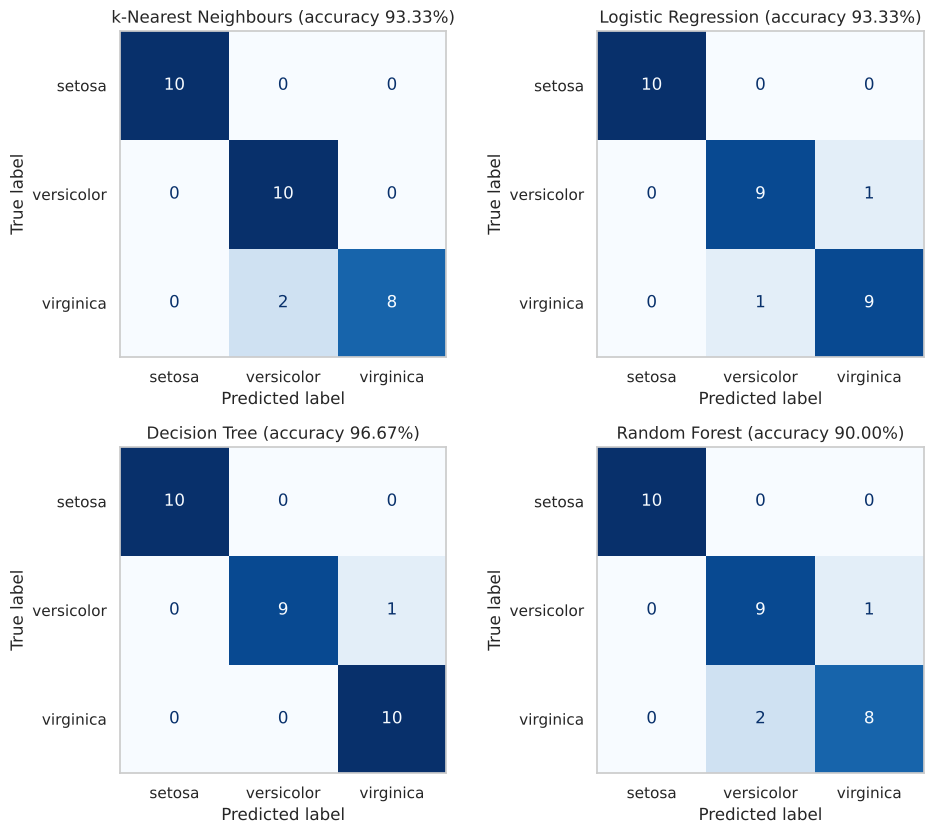

In [13]:
# Rows = true species, columns = predicted species. Numbers off the diagonal are mistakes.
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=TARGET_NAMES, cmap="Blues",
        colorbar=False, ax=ax)
    ax.set_title(f"{name} (accuracy {accuracy_score(y_test, pred):.2%})")
    ax.grid(False)
plt.tight_layout()
plt.show()

### 7.2 Classification reports (precision, recall, F1)

In [14]:
for name, pred in predictions.items():
    print("=" * 62)
    print(name)
    print("=" * 62)
    print(classification_report(y_test, pred, target_names=TARGET_NAMES, digits=3))

k-Nearest Neighbours
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.

### 📝 Evaluation notes

- All four models classify **Setosa perfectly** (precision and recall = 1.0).
- Every mistake is a confusion between **Versicolor** and **Virginica**, as predicted in Section 5.
- The test set has only **30 flowers**, so one wrong flower changes accuracy by about **3.3 percentage points**.
  Differences between the models on this single split are therefore small and can be luck.
  [Section 8](#8.-Model-comparison-and-best-model) adds cross-validation for a more reliable comparison.

---
## 8. Model comparison and best model

> **What happens here:** compare the models using the test accuracy **and** 5-fold stratified
> cross-validation. Cross-validation trains and tests each model five times on different splits,
> so it is much more trustworthy than a single 30-flower test set.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    rows.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, predictions[name]),
        "CV mean accuracy": cv_scores.mean(),
        "CV std": cv_scores.std(),
    })

results = (pd.DataFrame(rows)
             .sort_values("CV mean accuracy", ascending=False)
             .reset_index(drop=True))
results.round(4)

,Model,Test accuracy,CV mean accuracy,CV std
0,k-Nearest Neighbours,0.9333,0.9733,0.0249
1,Random Forest,0.9000,0.9600,0.0389
2,Decision Tree,0.9667,0.9600,0.0249
3,Logistic Regression,0.9333,0.9533,0.0452


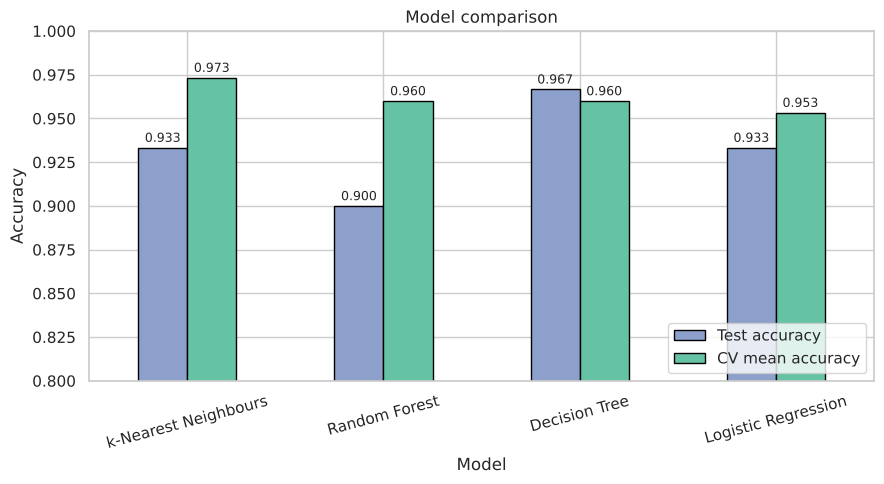

In [16]:
# Side-by-side bar chart
plot_df = results.set_index("Model")[["Test accuracy", "CV mean accuracy"]]
ax = plot_df.plot(kind="bar", figsize=(9, 5), color=["#8DA0CB", "#66C2A5"], edgecolor="black")
ax.set_ylim(0.8, 1.0)
ax.set_ylabel("Accuracy")
ax.set_title("Model comparison")
ax.legend(loc="lower right")
plt.xticks(rotation=15)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=9)
plt.tight_layout()
plt.show()

In [17]:
# Declare the best model: highest cross-validated accuracy
best_name = results.loc[0, "Model"]
best_cv = results.loc[0, "CV mean accuracy"]
best_std = results.loc[0, "CV std"]
best_test = results.loc[0, "Test accuracy"]

print(f"🏆 Best model: {best_name}")
print(f"   Cross-validated accuracy : {best_cv:.2%} (± {best_std:.2%})")
print(f"   Test-set accuracy        : {best_test:.2%}")

🏆 Best model: k-Nearest Neighbours
   Cross-validated accuracy : 97.33% (± 2.49%)
   Test-set accuracy        : 93.33%


### 🏆 Best model and justification

The best model is the one printed above, chosen by the **highest 5-fold cross-validated accuracy**.

**Why cross-validation and not just the test score?**
The single test set has only 30 flowers, so one mistake moves the score by 3.3 points. Cross-validation
uses all 150 flowers for testing across five rounds, which gives a steadier estimate.

**Honest reading of the table:** the models are all close (roughly 95% to 97% in cross-validation), and the gaps
are **smaller than the standard deviation**. So the ranking is a preference, not a proven winner. On a clean,
small dataset like Iris, several algorithms work almost equally well. For this reason the simplest model that
performs well is a sensible choice in practice.

---
## 9. Feature importance and a new prediction

> **What happens here:** (a) check numerically which features matter most, to confirm Section 5,
> and (b) use a trained model to predict a flower it has never seen.

### 9.1 Feature importance (Random Forest)

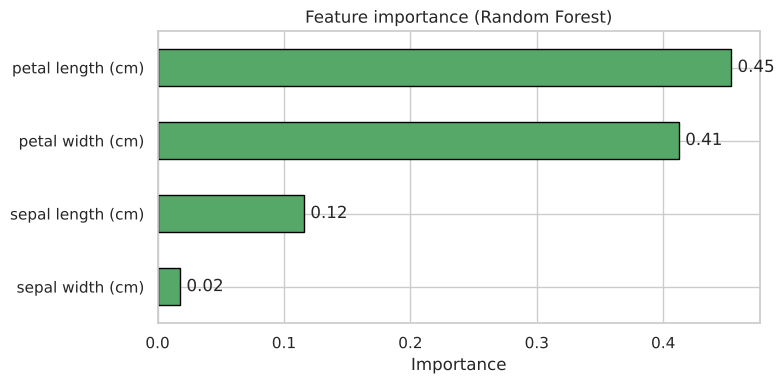

In [18]:
# kNN has no built-in importance, so a tree-based model is used to measure feature importance
rf = models["Random Forest"]
importance = (pd.Series(rf.feature_importances_, index=FEATURES)
                .sort_values())

ax = importance.plot(kind="barh", figsize=(8, 4), color="#55A868", edgecolor="black")
ax.set_title("Feature importance (Random Forest)")
ax.set_xlabel("Importance")
for i, v in enumerate(importance):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center")
plt.tight_layout()
plt.show()

**Result:** `petal length` and `petal width` together account for about **87%** of the importance,
while `sepal width` contributes very little. This **confirms the discussion in Section 5**.

### 9.2 Predicting a new flower

In [19]:
# A new, unseen flower: sepal length, sepal width, petal length, petal width (cm)
X_new = np.array([[5.0, 2.9, 1.0, 0.2]])

best_model = models[best_name]
prediction = best_model.predict(X_new)[0]

print(f"New flower measurements : {X_new[0]}")
print(f"Model used              : {best_name}")
print(f"Predicted species       : {TARGET_NAMES[prediction]}")

New flower measurements : [5.  2.9 1.  0.2]
Model used              : k-Nearest Neighbours
Predicted species       : setosa


The measurements show a very short petal (1.0 cm) and a very narrow petal (0.2 cm), the typical signature of
**Setosa**, so the prediction matches what the plots in Section 4 suggest.

---
## 10. Conclusion

### ✅ Summary

| Step | Result |
|---|---|
| Data | 150 flowers, 4 numeric features, 3 balanced classes, no missing values |
| Most useful features | **Petal length** and **petal width** |
| Models trained | kNN, Logistic Regression, Decision Tree, Random Forest |
| Test accuracy | Roughly 90% to 97% depending on the model (30 test flowers) |
| Cross-validated accuracy | Roughly 95% to 97% for all models |
| Hardest part | Separating **Versicolor** from **Virginica** |

### 💡 Key takeaways

1. Iris is an easy problem: simple models already reach about 95% or more.
2. **Setosa** is perfectly separable, and all errors involve Versicolor and Virginica.
3. A single small test set can be misleading, so cross-validation gave a fairer comparison.
4. Petal measurements carry most of the information.

### ⚠️ Limitations

- The dataset is small and clean, so these scores will not transfer directly to messy real-world data.
- Hyperparameters were set by hand (for example `k=5`, `max_depth=3`). A grid search could tune them.

### 🚀 Possible next steps

- Tune hyperparameters with `GridSearchCV`.
- Try other models such as SVM or Gradient Boosting.
- Visualise the decision boundaries on the two petal features.

---

### 📚 References

- scikit-learn User Guide: <https://scikit-learn.org>
- Fisher, R.A. (1936). *The use of multiple measurements in taxonomic problems.*
- Müller, A. & Guido, S. *Introduction to Machine Learning with Python.*

<p align="center"><i>Prepared for the Oasis Infobyte Internship Program · #oasisinfobyte · #datascience</i></p>